Training data: (623, 13)
Validation data: (134, 13)
Test data: (134, 13)
Everything is ready!
Training batches: 20
Validation batches: 5
Epoch 25 | Train Loss: 0.3807 | Validation Loss: 0.3354
Epoch 50 | Train Loss: 0.3641 | Validation Loss: 0.3601
Epoch 75 | Train Loss: 0.3354 | Validation Loss: 0.3637
Epoch 100 | Train Loss: 0.3165 | Validation Loss: 0.4362
Epoch 125 | Train Loss: 0.2866 | Validation Loss: 0.5570
Epoch 150 | Train Loss: 0.2363 | Validation Loss: 0.7049
Epoch 175 | Train Loss: 0.2126 | Validation Loss: 0.6894
Epoch 200 | Train Loss: 0.1981 | Validation Loss: 0.7554
Epoch 225 | Train Loss: 0.1883 | Validation Loss: 0.9342
Epoch 250 | Train Loss: 0.1638 | Validation Loss: 1.0818
Epoch 275 | Train Loss: 0.1768 | Validation Loss: 0.8694
Epoch 300 | Train Loss: 0.1515 | Validation Loss: 1.1278


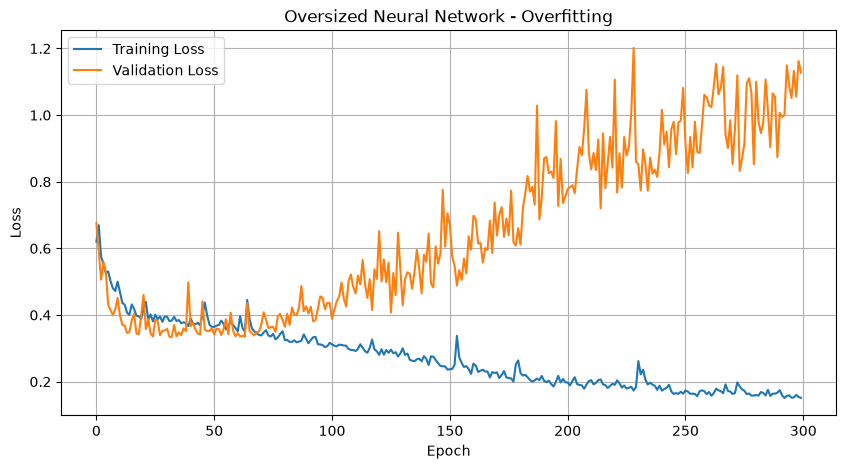

In [2]:
#22.Build an intentionally oversized network for your dataset and train it until the gap between
#training and validation loss is impossible to miss.
import seaborn as sb
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
titanic = sb.load_dataset("titanic")
X = titanic.drop(["survived", "alive"], axis=1)
y = titanic["survived"]
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765,random_state=42, stratify=y_temp)
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test.shape)
X_train = pd.get_dummies(X_train, dtype=int)
X_val = pd.get_dummies(X_val, dtype=int)
medians = X_train.median()
X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_train_tensor = torch.tensor(X_train.to_numpy(dtype="float32"))
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.long)
X_val_tensor = torch.tensor(X_val.to_numpy(dtype="float32"))
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.long)
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
print("Everything is ready!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
input_size = X_train_tensor.shape[1]
model = nn.Sequential(
    nn.Linear(input_size, 256),
    nn.ReLU(),
    nn.Linear(256, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 2))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_losses = []
val_losses = []
for epoch in range(300):
    model.train()
    total_train_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * len(y_batch)
    train_loss = total_train_loss / len(train_dataset)
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            predictions = model(X_batch)
            loss = loss_fn(predictions, y_batch)
            total_val_loss += loss.item() * len(y_batch)
    val_loss = total_val_loss / len(val_dataset)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    if (epoch + 1) % 25 == 0:
        print(f"Epoch {epoch + 1} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {val_loss:.4f}")
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Oversized Neural Network - Overfitting")
plt.legend()
plt.grid(True)
plt.show()


Training with Dropout = 0.2
Epoch 50 | Train Loss: 0.3971 | Validation Loss: 0.3601
Epoch 100 | Train Loss: 0.3688 | Validation Loss: 0.3501
Epoch 150 | Train Loss: 0.2968 | Validation Loss: 0.4577
Epoch 200 | Train Loss: 0.2596 | Validation Loss: 0.7579
Epoch 250 | Train Loss: 0.2331 | Validation Loss: 0.8071
Epoch 300 | Train Loss: 0.2295 | Validation Loss: 0.8039

Training with Dropout = 0.5
Epoch 50 | Train Loss: 0.4376 | Validation Loss: 0.3539
Epoch 100 | Train Loss: 0.3885 | Validation Loss: 0.3676
Epoch 150 | Train Loss: 0.3600 | Validation Loss: 0.3870
Epoch 200 | Train Loss: 0.3323 | Validation Loss: 0.4831
Epoch 250 | Train Loss: 0.3351 | Validation Loss: 0.4533
Epoch 300 | Train Loss: 0.3010 | Validation Loss: 0.4341


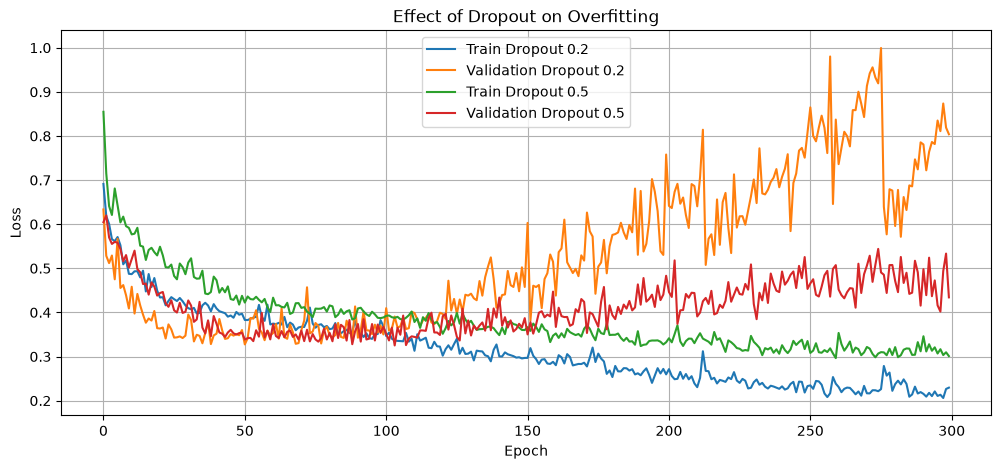

Dropout 0.2 | Final Train Loss: 0.2295 | Final Validation Loss: 0.8039 | Loss Gap: 0.5745
Dropout 0.5 | Final Train Loss: 0.3010 | Final Validation Loss: 0.4341 | Loss Gap: 0.1331


In [3]:
#23.Add dropout between the layers, try two different rates, and compare the gap before and after.
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
dropout_rates = [0.2, 0.5]
results = {}
for rate in dropout_rates:
    print(f"\nTraining with Dropout = {rate}")
    model=nn.Sequential(nn.Linear(input_size,256),nn.ReLU(),nn.Dropout(rate), nn.Linear(256, 256),nn.ReLU(),
        nn.Dropout(rate),nn.Linear(256, 128),nn.ReLU(),nn.Dropout(rate),nn.Linear(128, 2))
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    train_losses = []
    val_losses = []
    for epoch in range(300):
        model.train()
        total_train_loss = 0
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = loss_fn(predictions, y_batch)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * len(y_batch)
        train_loss = total_train_loss / len(train_loader.dataset)
        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                predictions = model(X_batch)
                loss = loss_fn(predictions, y_batch)
                total_val_loss += loss.item() * len(y_batch)
        val_loss = total_val_loss / len(val_loader.dataset)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        if (epoch + 1) % 50 == 0:
            print(
                f"Epoch {epoch + 1} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Validation Loss: {val_loss:.4f}")
    results[rate] = (train_losses, val_losses)
plt.figure(figsize=(12, 5))
for rate, (train_losses, val_losses) in results.items():
    plt.plot(train_losses, label=f"Train Dropout {rate}")
    plt.plot(val_losses, label=f"Validation Dropout {rate}")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Dropout on Overfitting")
plt.legend()
plt.grid(True)
plt.show()
for rate, (train_losses, val_losses) in results.items():
    gap = val_losses[-1] - train_losses[-1]
    print(
        f"Dropout {rate} | "
        f"Final Train Loss: {train_losses[-1]:.4f} | "
        f"Final Validation Loss: {val_losses[-1]:.4f} | "
        f"Loss Gap: {gap:.4f}"
    )

Epoch 50 | Train Loss: 0.4288 | Validation Loss: 0.3877
Epoch 100 | Train Loss: 0.4105 | Validation Loss: 0.3573
Epoch 150 | Train Loss: 0.3977 | Validation Loss: 0.3449
Epoch 200 | Train Loss: 0.3951 | Validation Loss: 0.3479
Epoch 250 | Train Loss: 0.3848 | Validation Loss: 0.3666
Epoch 300 | Train Loss: 0.3944 | Validation Loss: 0.3813


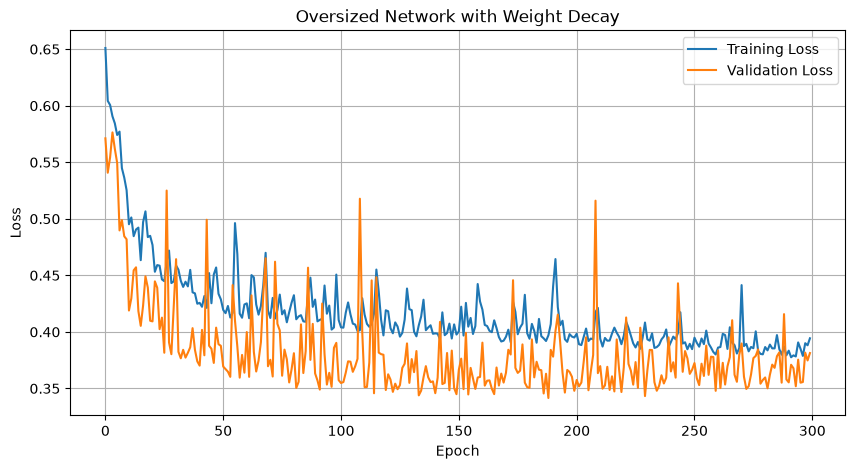

Final Training Loss: 0.3944
Final Validation Loss: 0.3813
Final Loss Gap: -0.013


In [4]:
# 24. Add weight decay and observe both loss curves
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
input_size = X_train_tensor.shape[1]
model = nn.Sequential(
    nn.Linear(input_size, 256),
    nn.ReLU(),
    nn.Linear(256, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 2))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.001,weight_decay=0.01)
train_losses = []
val_losses = []
for epoch in range(300):
    model.train()
    total_train_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * len(y_batch)
    train_loss = total_train_loss / len(train_loader.dataset)

    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            predictions = model(X_batch)
            loss = loss_fn(predictions, y_batch)
            total_val_loss += loss.item() * len(y_batch)
    val_loss = total_val_loss / len(val_loader.dataset)
    train_losses.append(train_loss)#
    val_losses.append(val_loss)
    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {val_loss:.4f}")
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Oversized Network with Weight Decay")
plt.legend()
plt.grid(True)
plt.show()
# Final loss gap
print("Final Training Loss:", round(train_losses[-1], 4))
print("Final Validation Loss:", round(val_losses[-1], 4))
print("Final Loss Gap:",round(val_losses[-1] - train_losses[-1], 4))

Epoch 10 | Train Loss: 0.4609 | Validation Loss: 0.4184
Epoch 20 | Train Loss: 0.4422 | Validation Loss: 0.4364
Epoch 30 | Train Loss: 0.3993 | Validation Loss: 0.3629
Epoch 40 | Train Loss: 0.3946 | Validation Loss: 0.3538
Early stopping at epoch 42
Best Validation Loss: 0.3371
Best model weights restored!


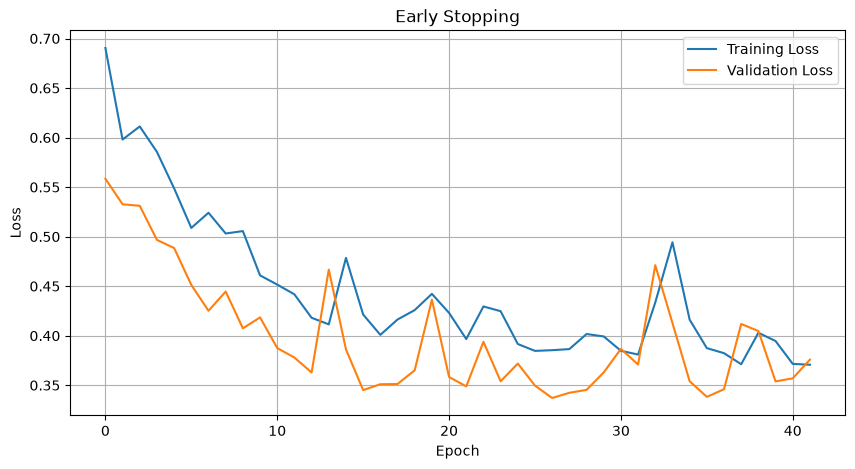

In [5]:
#25.	Implement early stopping yourself by tracking the best validation loss, saving the model state whenever it improves,
#and restoring that saved state at the end.
import copy
model = nn.Sequential(
    nn.Linear(input_size, 256),
    nn.ReLU(),
    nn.Linear(256, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 2)
)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_losses = []
val_losses = []
best_val_loss = float("inf")
best_model_state = None
patience = 15
counter = 0
for epoch in range(300):
    model.train()
    total_train_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * len(y_batch)
    train_loss = total_train_loss / len(train_loader.dataset)
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            predictions = model(X_batch)
            loss = loss_fn(predictions, y_batch)
            total_val_loss += loss.item() * len(y_batch)
    val_loss = total_val_loss / len(val_loader.dataset)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        counter = 0
    else:
        counter += 1
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {val_loss:.4f}"
        )
    if counter >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break
model.load_state_dict(best_model_state)
print("Best Validation Loss:", round(best_val_loss, 4))
print("Best model weights restored!")
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Early Stopping")
plt.legend()
plt.grid(True)
plt.show()


Epoch 10 | Train Loss: 0.4208 | Validation Loss: 0.3792 | Learning Rate: 0.001000
Epoch 20 | Train Loss: 0.3571 | Validation Loss: 0.3727 | Learning Rate: 0.000250
Epoch 30 | Train Loss: 0.3666 | Validation Loss: 0.3740 | Learning Rate: 0.000125
Epoch 40 | Train Loss: 0.3385 | Validation Loss: 0.3654 | Learning Rate: 0.000031
Epoch 50 | Train Loss: 0.3575 | Validation Loss: 0.3744 | Learning Rate: 0.000008
Epoch 60 | Train Loss: 0.3400 | Validation Loss: 0.3767 | Learning Rate: 0.000004
Epoch 70 | Train Loss: 0.3504 | Validation Loss: 0.3762 | Learning Rate: 0.000001
Epoch 80 | Train Loss: 0.3475 | Validation Loss: 0.3790 | Learning Rate: 0.000000
Epoch 90 | Train Loss: 0.3428 | Validation Loss: 0.3694 | Learning Rate: 0.000000
Epoch 100 | Train Loss: 0.3368 | Validation Loss: 0.3710 | Learning Rate: 0.000000


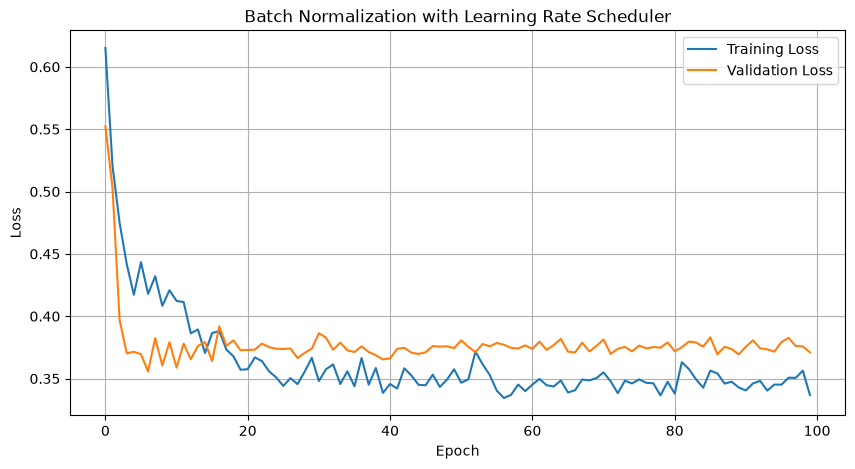

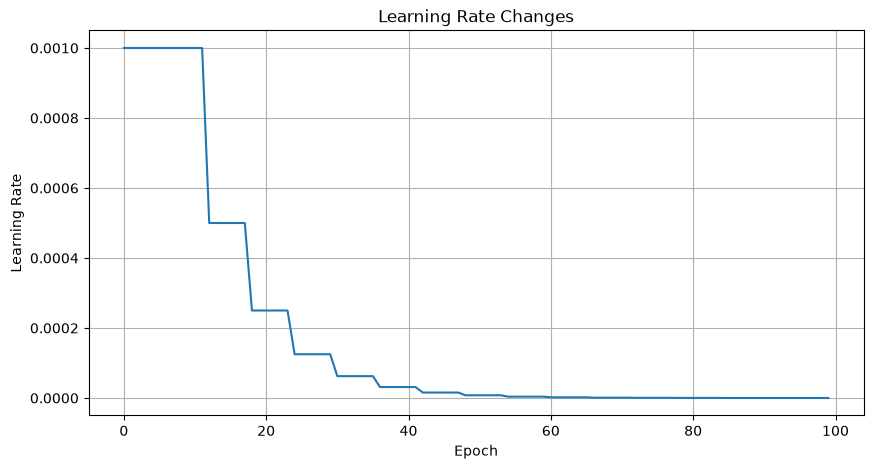

In [6]:
#26.Add batch normalization and note any change in both the stability of training and the speed at which the loss falls.
#27.Add a scheduler that reduces the learning rate whenever validation loss stops improving for a few epochs.
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
model = nn.Sequential(
    nn.Linear(input_size, 256),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.BatchNorm1d(128),
    nn.ReLU(),
    nn.Linear(128, 2)
)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)
train_losses = []
val_losses = []
learning_rates = []
for epoch in range(100):
    model.train()
    total_train_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * len(y_batch)
    train_loss = total_train_loss / len(train_loader.dataset)
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            predictions = model(X_batch)
            loss = loss_fn(predictions, y_batch)
            total_val_loss += loss.item() * len(y_batch)
    val_loss = total_val_loss / len(val_loader.dataset)
    scheduler.step(val_loss)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    learning_rates.append(optimizer.param_groups[0]["lr"])
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {val_loss:.4f} | "
            f"Learning Rate: {optimizer.param_groups[0]['lr']:.6f}"
        )
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Batch Normalization with Learning Rate Scheduler")
plt.legend()
plt.grid(True)
plt.show()
plt.figure(figsize=(10, 5))
plt.plot(learning_rates)
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Changes")
plt.grid(True)
plt.show()
